In [1]:
import os
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = "/content/drive/MyDrive/customers-like-you"
except ImportError:
    BASE = "."          # running locally from the repo folder

for d in ["data/raw", "data/processed", "outputs", "outputs/slides"]:
    os.makedirs(f"{BASE}/{d}", exist_ok=True)
print("Working in:", os.path.abspath(BASE))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working in: /content/drive/MyDrive/customers-like-you


In [2]:
import pandas as pd
sheets = pd.read_excel(f"{BASE}/data/raw/online_retail_II.xlsx", sheet_name=None)
print({name: len(s) for name, s in sheets.items()})
print(sum(len(s) for s in sheets.values()))
print([s.columns.tolist() for s in sheets.values()])

{'Year 2009-2010': 525461, 'Year 2010-2011': 541910}
1067371
[['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country'], ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']]


In [3]:
df = pd.concat(sheets.values(), ignore_index=True)

for col in ["Invoice", "StockCode", "Description", "Country"]:
    df[col] = df[col].astype("string")

df.to_parquet(f"{BASE}/data/raw/retail.parquet")

In [4]:
df2 = pd.read_parquet(f"{BASE}/data/raw/retail.parquet")
print(len(df2))
print(df2.dtypes)
print(df2.drop(columns=["Customer ID"]).head())

1067371
Invoice        string[python]
StockCode      string[python]
Description    string[python]
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country        string[python]
dtype: object
  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

          InvoiceDate  Price         Country  
0 2009-12-01 07:45:00   6.95  United Kingdom  
1 2009-12-01 07:45:00   6.75  United Kingdom  
2 2009-12-01 07:45:00   6.75  United Kingdom  
3 2009-12-01 07:45:00   2.10  United Kingdom  
4 2009-12-01 07:45:00   1.25  United Kingdom  


In [5]:
import pandas as pd
df = pd.read_parquet(f"{BASE}/data/raw/retail.parquet")

# 1. The profile table: type, missing values, unique values per column
profile = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(),
})
print(profile)
profile.to_csv(f"{BASE}/outputs/data_profile.csv")

# 2. Numeric columns: look for negatives and zeros
print(df[["Quantity", "Price"]].describe())

# 3. Things DE2 will have to clean
print("\nCancellations (Invoice starts with C):", df["Invoice"].str.startswith("C", na=False).sum())
print("Quantity <= 0:", (df["Quantity"] <= 0).sum())
print("Price <= 0:", (df["Price"] <= 0).sum())
print("Missing Customer ID:", df["Customer ID"].isna().sum())

# 4. Non-product stock codes (those with no digits at all, like POST, M, D)
non_prod = df[~df["StockCode"].str.contains(r"\d", na=False)]["StockCode"].value_counts()
print("\nNon-product codes:\n", non_prod)

# 5. Date range
print("\nDates:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

                      dtype  missing  missing_%  unique
Invoice              string        0       0.00   53628
StockCode            string        0       0.00    5305
Description          string     4382       0.41    5698
Quantity              int64        0       0.00    1057
InvoiceDate  datetime64[ns]        0       0.00   47635
Price               float64        0       0.00    2807
Customer ID         float64   243007      22.77    5942
Country              string        0       0.00      43
           Quantity         Price
count  1.067371e+06  1.067371e+06
mean   9.938898e+00  4.649388e+00
std    1.727058e+02  1.235531e+02
min   -8.099500e+04 -5.359436e+04
25%    1.000000e+00  1.250000e+00
50%    3.000000e+00  2.100000e+00
75%    1.000000e+01  4.150000e+00
max    8.099500e+04  3.897000e+04

Cancellations (Invoice starts with C): 19494
Quantity <= 0: 22950
Price <= 0: 6207
Missing Customer ID: 243007

Non-product codes:
 StockCode
POST            2122
DOT             1446
M    

In [6]:
import os
import pandas as pd

df = pd.read_parquet(f"{BASE}/data/raw/retail.parquet")

# Tidy codes first (not a removal rule)
df["StockCode"] = df["StockCode"].str.strip().str.upper()

log = []
def apply_rule(data, name, keep_mask):
    before = len(data)
    out = data[keep_mask(data)]
    log.append({"rule": name, "rows_before": before,
                "rows_removed": before - len(out), "rows_after": len(out)})
    return out

df = apply_rule(df, "1. Missing Customer ID", lambda d: d["Customer ID"].notna())
df = apply_rule(df, "2. Cancellation invoices (start with C)", lambda d: ~d["Invoice"].str.startswith("C", na=False))
df = apply_rule(df, "3. Quantity <= 0", lambda d: d["Quantity"] > 0)
df = apply_rule(df, "4. Price <= 0", lambda d: d["Price"] > 0)
df = apply_rule(df, "5. Non-product stock codes", lambda d: d["StockCode"].str.match(r"^\d{5}[A-Z]*$", na=False))
df = apply_rule(df, "6. Purchases fully reversed by an exact cancellation (2 lines)",
                lambda d: ~(((d["StockCode"] == "23843") & (d["Quantity"] == 80995)) |
                            ((d["StockCode"] == "23166") & (d["Quantity"] == 74215))))

df["Customer ID"] = df["Customer ID"].astype(int)

cleaning_log = pd.DataFrame(log)
cleaning_log["removed_%_of_raw"] = (cleaning_log["rows_removed"] / 1_067_371 * 100).round(2)
print(cleaning_log.to_string(index=False))

# Save outputs
os.makedirs(f"{BASE}/data/processed", exist_ok=True)
cleaning_log.to_csv(f"{BASE}/outputs/cleaning_log.csv", index=False)
df.to_parquet(f"{BASE}/data/processed/clean.parquet")

# Quick sanity check
print("\nRows left:", len(df))
print("Customers:", df["Customer ID"].nunique())
print("Products:", df["StockCode"].nunique())
print("Dates:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())
print(df[["Quantity", "Price"]].describe())

                                                          rule  rows_before  rows_removed  rows_after  removed_%_of_raw
                                        1. Missing Customer ID      1067371        243007      824364             22.77
                       2. Cancellation invoices (start with C)       824364         18744      805620              1.76
                                              3. Quantity <= 0       805620             0      805620              0.00
                                                 4. Price <= 0       805620            71      805549              0.01
                                    5. Non-product stock codes       805549          2917      802632              0.27
6. Purchases fully reversed by an exact cancellation (2 lines)       802632             2      802630              0.00

Rows left: 802630
Customers: 5852
Products: 4618
Dates: 2009-12-01 07:45:00 to 2011-12-09 12:50:00
            Quantity          Price
count  802630.000000  80

In [7]:
decision_log = """# Decision Log

## DE2 Cleaning
- Removed lines with no Customer ID: cannot be linked to a customer.
- Removed cancellations (Invoice starts with C): not purchases.
- Removed Quantity <= 0 and Price <= 0: returns, adjustments, free or accounting lines.
- Kept only StockCodes matching 5 digits + optional letters: removes postage, fees,
  manual entries, vouchers and test codes, which are not recommendable products.
- Normalised StockCode (strip, uppercase) so variants like 'm' and 'M' are treated alike.
- Rule order matters for the log: each row is counted under the first rule that removes it.
- Not done: duplicate lines were kept (repeated lines can be genuine repeat purchases).
- Removed two purchases that were fully reversed by an exact-quantity cancellation (80,995 units of 23843, cancelled by C581484; 74,215 units of 23166, cancelled by C541433). The pipeline drops cancellation lines but not the orders they reverse, so these two would have stayed as phantom purchases. Not done: netting every cancellation against its original order; the other reversals are small and are damped by log(1 + quantity).
"""
with open(f"{BASE}/decision_log.md", "w") as f:
    f.write(decision_log)

In [8]:
import numpy as np, pandas as pd, scipy.sparse as sp

df = pd.read_parquet(f"{BASE}/data/processed/clean.parquet")
MIN_CUSTOMERS = 10

last_day   = df["InvoiceDate"].max().normalize()
test_start = last_day - pd.DateOffset(months=2)      # 2011-10-09
val_start  = test_start - pd.DateOffset(months=2)    # 2011-08-09
print("Validation starts:", val_start.date(), "| Test starts:", test_start.date())

def build_phase(fit, evalset, files):
    """fit = rows the model may see; evalset = later rows to hold out from (R2)."""
    # --- DE3: hold out only products the customer never bought in the fit period ---
    seen = set(zip(fit["Customer ID"], fit["StockCode"]))
    known = evalset[evalset["Customer ID"].isin(set(fit["Customer ID"]))]
    is_new = [(c, p) not in seen for c, p in zip(known["Customer ID"], known["StockCode"])]
    held = known[is_new].copy()
    assert fit["InvoiceDate"].max() < evalset["InvoiceDate"].min()          # no date overlap
    assert len(set(zip(held["Customer ID"], held["StockCode"])) & seen) == 0  # no pair overlap

    # --- DE4: sparse matrix from the fit period only ---
    agg = fit.groupby(["Customer ID", "StockCode"], as_index=False)["Quantity"].sum()
    n_buyers = agg.groupby("StockCode")["Customer ID"].nunique()
    keep = n_buyers[n_buyers >= MIN_CUSTOMERS].index
    agg = agg[agg["StockCode"].isin(keep)].copy()
    agg["value"] = np.log1p(agg["Quantity"])
    cust_ids = np.sort(agg["Customer ID"].unique())
    prod_ids = np.sort(agg["StockCode"].unique())
    cust_idx = {c: i for i, c in enumerate(cust_ids)}
    prod_idx = {p: j for j, p in enumerate(prod_ids)}
    A = sp.csr_matrix((agg["value"].to_numpy(),
                       (agg["Customer ID"].map(cust_idx).to_numpy(),
                        agg["StockCode"].map(prod_idx).to_numpy())),
                      shape=(len(cust_ids), len(prod_ids)))

    held_f = held[held["Customer ID"].isin(cust_idx) & held["StockCode"].isin(prod_idx)]
    names = (fit.dropna(subset=["Description"])
             .groupby("StockCode")["Description"].agg(lambda s: s.mode().iloc[0]))

    f_A, f_cust, f_prod, f_held = files
    sp.save_npz(f"{BASE}/data/processed/{f_A}", A)
    pd.DataFrame({"idx": range(len(cust_ids)), "customer_id": cust_ids}).to_csv(
        f"{BASE}/data/processed/{f_cust}", index=False)
    pd.DataFrame({"idx": range(len(prod_ids)), "stock_code": prod_ids,
                  "description": names.reindex(prod_ids).values}).to_csv(
        f"{BASE}/data/processed/{f_prod}", index=False)
    held_f.to_parquet(f"{BASE}/data/processed/{f_held}")

    pairs = held[["Customer ID", "StockCode"]].drop_duplicates()
    pairs_f = held_f[["Customer ID", "StockCode"]].drop_duplicates()
    return pd.Series({
        "fit_ends_before": str(fit["InvoiceDate"].max().date() + pd.Timedelta(days=1)),
        "fit_rows": len(fit),
        "fit_customers": fit["Customer ID"].nunique(),
        "fit_products": fit["StockCode"].nunique(),
        "eval_rows_raw": len(evalset),
        "eval_customers_total": evalset["Customer ID"].nunique(),
        "eval_customers_new_not_in_fit": len(set(evalset["Customer ID"]) - set(fit["Customer ID"])),
        "heldout_pairs": len(pairs),
        "matrix_customers": A.shape[0],
        "matrix_products": A.shape[1],
        "matrix_nonzeros": A.nnz,
        "heldout_pairs_after_product_filter": len(pairs_f),
        "eval_customers_left": pairs_f["Customer ID"].nunique(),
    })

# Phase 1: TUNING (fit before Aug 9, hold out the validation period)
fit_tune  = df[df["InvoiceDate"] < val_start]
val_rows  = df[(df["InvoiceDate"] >= val_start) & (df["InvoiceDate"] < test_start)]
rep_val = build_phase(fit_tune, val_rows,
                      ("A_tune.npz", "customer_index_tune.csv", "product_index_tune.csv", "val_filtered.parquet"))

# Phase 2: FINAL (fit before Oct 9, hold out the test period)
fit_final = df[df["InvoiceDate"] < test_start]
test_rows = df[df["InvoiceDate"] >= test_start]
rep_test = build_phase(fit_final, test_rows,
                       ("A_train.npz", "customer_index.csv", "product_index.csv", "test_filtered.parquet"))
fit_final.to_parquet(f"{BASE}/data/processed/train.parquet")   # used later for countries and revenue

report = pd.DataFrame({"validation (tuning)": rep_val, "test (final)": rep_test})
print(report.to_string())
report.to_csv(f"{BASE}/outputs/split_report.csv")

Validation starts: 2011-08-09 | Test starts: 2011-10-09
                                   validation (tuning) test (final)
fit_ends_before                             2011-08-09   2011-10-08
fit_rows                                        612498       683669
fit_customers                                     5150         5472
fit_products                                      4385         4529
eval_rows_raw                                    71171       118961
eval_customers_total                              1845         2422
eval_customers_new_not_in_fit                      322          380
heldout_pairs                                    29532        49646
matrix_customers                                  5149         5471
matrix_products                                   3492         3686
matrix_nonzeros                                 373743       413690
heldout_pairs_after_product_filter               24227        44922
eval_customers_left                               1400      

In [9]:
with open(f"{BASE}/decision_log.md", "a") as f:
    f.write("""
## DE3 Split (three periods)
- Test = last 2 months (from 9 Oct 2011). Validation = the 2 months before (from 9 Aug 2011). Train = everything earlier.
- Two phases: TUNING fits on train and is scored on validation (used to choose k and the blend weight).
  FINAL fits on train + validation and is scored on test, once. This keeps test data out of every modelling choice (R2).
- Customers not seen in the fit period are excluded from evaluation (cold start) and counted in split_report.csv.
- Held-out = products a customer never bought in the fit period, so we measure discovery, not repeat buying.
- Assertions check no date overlap and no customer-product pair overlap in both phases.
- The 80,995-unit order (9 Dec 2011) is removed in DE2, so it cannot appear as a held-out purchase.
- The validation window (Aug-Oct) is less Christmas-heavy than the test window (Oct-Dec), so the best settings may transfer imperfectly.

## DE4 Matrix
- Purchase value = log(1 + total quantity per customer-product pair); sum first, then log.
- Raw quantity rejected: a few very large wholesale lines (thousands of units) would dominate. Log-quantity vs 1/0 compared in ML4/ML5; raw counts not tested.
- Product filter: bought by >= 10 distinct customers in the FIT period only (R2), recomputed in each phase.
- Evaluation pairs on filtered-out products or unknown customers are dropped and counted.
- Tuning files carry the suffix _tune; final files keep the plain names. Index maps contain customer IDs: never committed or shown (R4).
""")

In [10]:
import numpy as np, scipy.sparse as sp, pandas as pd

A = sp.load_npz(f"{BASE}/data/processed/A_train.npz")
n_cust, n_prod = A.shape
total_cells = n_cust * n_prod

dense_mb = total_cells * 8 / 1e6
sparse_mb = (A.data.nbytes + A.indices.nbytes + A.indptr.nbytes) / 1e6
k = 50
factors_mb = (n_cust + n_prod) * k * 8 / 1e6

matrix_report = pd.Series({
    "customers (rows)": n_cust,
    "products (columns)": n_prod,
    "total cells": total_cells,
    "non-zero cells": A.nnz,
    "density %": round(A.nnz / total_cells * 100, 2),
    "sparsity %": round((1 - A.nnz / total_cells) * 100, 2),
    "avg products per customer": round(A.nnz / n_cust, 1),
    "avg customers per product": round(A.nnz / n_prod, 1),
    "dense memory (MB)": round(dense_mb, 1),
    "sparse CSR memory (MB)": round(sparse_mb, 1),
    "factors at k=50 (MB)": round(factors_mb, 1),
})
print(matrix_report)
matrix_report.to_csv(f"{BASE}/outputs/matrix_report.csv")

customers (rows)                 5471.00
products (columns)               3686.00
total cells                  20166106.00
non-zero cells                 413690.00
density %                           2.05
sparsity %                         97.95
avg products per customer          75.60
avg customers per product         112.20
dense memory (MB)                 161.30
sparse CSR memory (MB)              5.00
factors at k=50 (MB)                3.70
dtype: float64


In [11]:
with open(f"{BASE}/decision_log.md", "a") as f:
    f.write("""
## DE5 Matrix report
- Dense vs sparse vs k=50 factors measured in matrix_report.csv.
- Finding: sparse storage already gives most of the size saving (161 MB dense, 5 MB sparse, 3.7 MB factors). SVD's value is a compact model that scores quickly; on its own it did not beat the best-seller baseline (see ML4).
""")

In [12]:
import scipy.sparse as sp
P = f"{BASE}/data/processed"
before = {n: sp.load_npz(f"{P}/{n}") for n in ["A_tune.npz", "A_train.npz"]}

!python {BASE}/build_matrix.py

for n, old in before.items():
    new = sp.load_npz(f"{P}/{n}")
    print(n, "| same shape:", old.shape == new.shape, "| identical values:", (old != new).nnz == 0)

Raw rows: 1067371
                                                          rule  rows_before  rows_removed  rows_after  removed_%_of_raw
                                        1. Missing Customer ID      1067371        243007      824364             22.77
                       2. Cancellation invoices (start with C)       824364         18744      805620              1.76
                                              3. Quantity <= 0       805620             0      805620              0.00
                                                 4. Price <= 0       805620            71      805549              0.01
                                    5. Non-product stock codes       805549          2917      802632              0.27
6. Purchases fully reversed by an exact cancellation (2 lines)       802632             2      802630              0.00
                                   validation (tuning) test (final)
fit_ends_before                             2011-08-09   2011-10-08
fit_ro

In [13]:
with open(f"{BASE}/README.md") as f:
    txt = f.read()
txt = txt.replace("## How to run\n- TBD", """## How to run
1. Put online_retail_II.xlsx in data/raw/ (not committed to Git).
2. pip install -r requirements.txt
3. python build_matrix.py   (rebuilds the cleaned data, split, sparse matrix and reports; seed = 42)
4. Open the analysis notebook and run top to bottom.""")
with open(f"{BASE}/README.md", "w") as f:
    f.write(txt)

In [14]:
decision_note = """# ML1: Method decision (written BEFORE fitting any model)

## Choice
Main model: Truncated SVD (TruncatedSVD, no centring). Comparison model: PCA, same k, same matrix (ML5).

## Why
- Goal is product recommendations: SVD is the standard latent-factor method for this.
- The matrix is 98% sparse (5,471 x 3,686; 413,690 non-zeros). SVD works on sparse input natively.
- PCA centres columns, so zeros become negatives and the matrix becomes dense (161 MB vs 5 MB).
  Even with implicit centring, PCA describes deviation from the average customer, not what people buy.
- Customer and product factors come from one fit (U*S and V), which is what a recommender needs.

## Predictions (to check in ML5)
1. SVD component 1 = overall purchase volume / popular products; PCA component 1 = a contrast between customer types.
2. PCA will be slower and use more peak memory than SVD.
3. SVD hit rate at 10 >= PCA hit rate at 10.
4. Risk: SVD component 1 may encode popularity, pushing recommendations toward best sellers.
   If hit rate barely beats the baseline, we report that honestly.

## k values to test (ML2)
10, 20, 50, 100, 200. Choose k from the error curve plus the hit rate, not from one number.
"""
with open(f"{BASE}/decision_log.md", "a") as f:
    f.write("\n" + decision_note)
with open(f"{BASE}/outputs/ml1_decision_note.md", "w") as f:
    f.write(decision_note)
print("Saved.")

Saved.


In [15]:
import time, numpy as np, pandas as pd, scipy.sparse as sp
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

SEED = 42
P = f"{BASE}/data/processed"

# ---- Tuning data only: fit before 9 Aug, held out = validation period (R2: no test files) ----
A_t = sp.load_npz(f"{P}/A_tune.npz").tocsr()
cust_t = pd.read_csv(f"{P}/customer_index_tune.csv")
prod_t = pd.read_csv(f"{P}/product_index_tune.csv", dtype={"stock_code": str})
val = pd.read_parquet(f"{P}/val_filtered.parquet")

c_map = dict(zip(cust_t["customer_id"], cust_t["idx"]))
p_map = dict(zip(prod_t["stock_code"], prod_t["idx"]))
pairs = val[["Customer ID", "StockCode"]].drop_duplicates().copy()
pairs["c"] = pairs["Customer ID"].map(c_map)
pairs["p"] = pairs["StockCode"].map(p_map)
assert pairs[["c", "p"]].notna().all().all()
held_v = pairs.groupby("c")["p"].apply(set).to_dict()
rows_v = np.array(sorted(held_v))
print("Validation customers evaluated:", len(rows_v), "| matrix:", A_t.shape)

def fit_product_vectors(A, k, seed=SEED):
    svd = TruncatedSVD(n_components=k, random_state=seed).fit(A)
    return normalize(svd.components_.T)

def recommend_with(A, score_fn, n=10, batch=1000):
    out = np.empty((A.shape[0], n), dtype=int)
    for start in range(0, A.shape[0], batch):
        block = A[start:start + batch]
        scores = np.asarray(score_fn(block), dtype=float)
        scores[block.nonzero()] = -np.inf          # never recommend what they already bought
        idx = np.argpartition(-scores, n, axis=1)[:, :n]
        part = np.take_along_axis(scores, idx, axis=1)
        out[start:start + batch] = np.take_along_axis(idx, np.argsort(-part, axis=1), axis=1)
    return out

def hit_v(recs):
    hits = np.array([len(set(recs[r]) & held_v[r]) > 0 for r in rows_v])
    p = hits.mean()
    return p, np.sqrt(p * (1 - p) / len(hits))

pop = np.asarray((A_t > 0).sum(axis=0)).ravel()      # distinct buyers per product
pop_n = pop / pop.max()

# ---- Best-seller baseline on validation ----
base_p, base_se = hit_v(recommend_with(A_t, lambda b: np.tile(pop_n, (b.shape[0], 1))))
print(f"Best-seller baseline (validation): {base_p:.1%} (+/- {base_se:.1%})")

# ---- Grid: k x blend weight (w=0 is plain SVD; large w approaches pure best sellers) ----
ks = [10, 20, 50, 100, 200]
ws = [0, 0.5, 1, 2, 4, 8]
grid = {}
t0 = time.time()
for k in ks:
    P_k = fit_product_vectors(A_t, k)
    for w in ws:
        def score(b, P_k=P_k, w=w):
            s = (b @ P_k) @ P_k.T
            s = s / (np.abs(s).max(axis=1, keepdims=True) + 1e-9)
            return s + w * pop_n
        grid[(k, w)] = hit_v(recommend_with(A_t, score))
print(f"Grid done in {time.time() - t0:.0f} s")

tab = pd.DataFrame({f"w={w}": {k: round(grid[(k, w)][0] * 100, 1) for k in ks} for w in ws})
tab.index.name = "k"
print("\nValidation hit rate at 10 (%), approx. standard error +/-1.2:")
print(tab.to_string())

# ---- Pre-committed selection rule ----
best_k, best_w = max(grid, key=lambda kw: grid[kw][0])
best_p, best_se = grid[(best_k, best_w)]
within = [kw for kw, (p, se) in grid.items() if p >= best_p - best_se]
chosen_k, chosen_w = min(within)                      # smallest k, then smallest w
print(f"\nBest cell: k={best_k}, w={best_w} -> {best_p:.1%} (+/- {best_se:.1%})")
print(f"Chosen (simplest within 1 SE): k={chosen_k}, w={chosen_w} -> {grid[(chosen_k, chosen_w)][0]:.1%}")
print(f"Plain SVD (w=0) at k={chosen_k}: {grid[(chosen_k, 0)][0]:.1%} | baseline: {base_p:.1%}")
if best_w == ws[-1]:
    print("WARNING: best weight is at the edge of the grid; extend ws upward.")

(pd.DataFrame([{"k": k, "w": w, "hit_rate": p, "se": se} for (k, w), (p, se) in grid.items()])
   .to_csv(f"{BASE}/outputs/tuning_grid_validation.csv", index=False))

Validation customers evaluated: 1400 | matrix: (5149, 3492)
Best-seller baseline (validation): 25.6% (+/- 1.2%)
Grid done in 24 s

Validation hit rate at 10 (%), approx. standard error +/-1.2:
      w=0  w=0.5   w=1   w=2   w=4   w=8
k                                       
10   14.8   20.1  25.6  30.7  28.7  26.8
20   18.2   22.0  26.5  31.1  28.9  26.8
50   22.4   26.1  28.7  34.5  29.8  27.1
100  22.6   26.6  31.7  32.9  28.6  26.6
200  21.6   25.0  29.7  30.4  26.9  26.4

Best cell: k=50, w=2 -> 34.5% (+/- 1.3%)
Chosen (simplest within 1 SE): k=50, w=2 -> 34.5%
Plain SVD (w=0) at k=50: 22.4% | baseline: 25.6%


In [16]:
with open(f"{BASE}/decision_log.md", "a") as f:
    f.write("""
## ML2/ML4 Tuning on the VALIDATION period (test data not used)
- Fit on data before 9 Aug 2011 (matrix 5,149 x 3,492); scored on the 9 Aug - 9 Oct purchases of 1,400 customers.
- Rule fixed BEFORE seeing results: take the best validation hit rate, then the smallest k (then smallest blend weight) within 1 standard error of it.
- Grid: k in {10, 20, 50, 100, 200} x popularity weight w in {0, 0.5, 1, 2, 4, 8}. Full table: outputs/tuning_grid_validation.csv.
- Result: best cell k=50, w=2 at 34.5% (+/-1.3). Nothing else within 1 SE, so chosen: k=50, w=2.
- Best-seller baseline on validation: 25.6% (+/-1.2). Plain SVD (w=0) at k=50: 22.4%, below the baseline.
- The optimum is inside the grid (w=4: 29.8%, w=8: 27.1%), so the grid was wide enough.
- 34.5% is the maximum over 30 settings, so it is optimistic. The test period is evaluated once, with these settings fixed.
""")

  k  fit_seconds  relative_error  info_kept_%  factors_MB
 10         0.24          0.8761         23.2         0.7
 20         0.28          0.8459         28.4         1.5
 50         0.56          0.7898         37.6         3.7
100         1.30          0.7279         47.0         7.3
200         4.72          0.6394         59.1        14.7


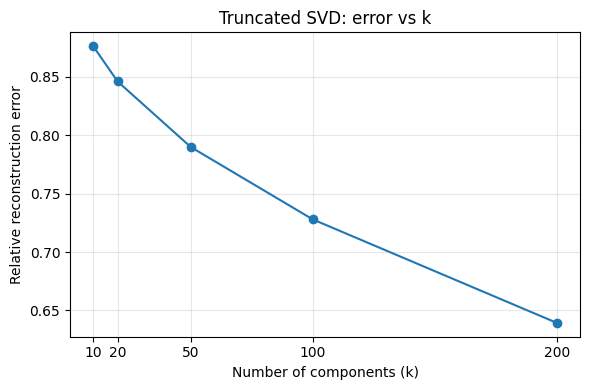

In [17]:
import time, numpy as np, pandas as pd, scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD

SEED = 42
A = sp.load_npz(f"{BASE}/data/processed/A_train.npz")
norm_A = spla.norm(A)            # Frobenius norm of the full matrix

rows = []
for k in [10, 20, 50, 100, 200]:
    t = time.time()
    svd = TruncatedSVD(n_components=k, random_state=SEED).fit(A)
    fit_s = time.time() - t

    US = svd.transform(A)                                  # customer factors
    rel_err = np.sqrt(max(norm_A**2 - np.linalg.norm(US)**2, 0)) / norm_A
    factors_mb = (A.shape[0] + A.shape[1]) * k * 8 / 1e6

    rows.append({"k": k, "fit_seconds": round(fit_s, 2),
                 "relative_error": round(rel_err, 4),
                 "info_kept_%": round((1 - rel_err**2) * 100, 1),
                 "factors_MB": round(factors_mb, 1)})

curve = pd.DataFrame(rows)
print(curve.to_string(index=False))
curve.to_csv(f"{BASE}/outputs/svd_k_curve.csv", index=False)

# Plot
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(curve["k"], curve["relative_error"], marker="o")
ax.set_xlabel("Number of components (k)")
ax.set_ylabel("Relative reconstruction error")
ax.set_title("Truncated SVD: error vs k")
ax.set_xticks(curve["k"])
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{BASE}/outputs/svd_error_vs_k.png", dpi=150)
plt.show()

In [18]:
import numpy as np, pandas as pd, scipy.sparse as sp
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

SEED = 42
A = sp.load_npz(f"{BASE}/data/processed/A_train.npz").tocsr()
prod = pd.read_csv(f"{BASE}/data/processed/product_index.csv")
names = prod["description"].fillna("?").tolist()

def fit_product_vectors(A, k, seed=SEED):
    """Fit Truncated SVD; return unit-length product vectors (n_products x k)."""
    svd = TruncatedSVD(n_components=k, random_state=seed).fit(A)
    return normalize(svd.components_.T)

def similar_products(P_vec, j, n=10):
    """Product-page box: the n most similar products to product j."""
    s = P_vec @ P_vec[j]
    s[j] = -np.inf
    top = np.argpartition(-s, n)[:n]
    return top[np.argsort(-s[top])]

def recommend(A, P_vec, n=10, batch=1000):
    """Top-n unseen products for every customer (rows of A). Returns an index array."""
    out = np.empty((A.shape[0], n), dtype=int)
    for start in range(0, A.shape[0], batch):
        block = A[start:start + batch]
        scores = (block @ P_vec) @ P_vec.T         # customer profile -> product scores
        scores[block.nonzero()] = -np.inf          # never recommend what they already bought
        idx = np.argpartition(-scores, n, axis=1)[:, :n]
        part = np.take_along_axis(scores, idx, axis=1)
        order = np.argsort(-part, axis=1)
        out[start:start + batch] = np.take_along_axis(idx, order, axis=1)
    return out

# ---- Fit at the provisional k and sanity-check ----
P_vec = fit_product_vectors(A, k=50)
print("Product vectors:", P_vec.shape)

# Sanity check: do the "also bought" products make sense?
for j in [10, 500, 2000]:
    print(f"\nProduct page for: {names[j]}")
    for r in similar_products(P_vec, j):
        print("   ->", names[r])

# Recommendations for all customers (anonymised by row number only: R4)
import time
t = time.time()
recs = recommend(A, P_vec)
print(f"\nScored all {A.shape[0]} customers in {time.time() - t:.2f} s")
print("Customer row 0 gets:", [names[j] for j in recs[0]])

Product vectors: (3686, 50)

Product page for: ASSORTED COLOUR JUMBO PEN
   -> DOTS IRONING BOARD COVER
   -> 4 PINK FLOCK CHRISTMAS BALLS
   -> WHITE TRAVEL ALARM CLOCK
   -> CAMOUFLAGE DESIGN TEDDY
   -> FUSCHIA RETRO BAR STOOL
   -> TROPICAL HOLIDAY PURSE 
   -> TOP SECRET PEN SET
   -> PINK SMALL JEWELLED PHOTOFRAME
   -> GIANT BLACK SUNGLASSES
   -> 4 GOLD FLOCK CHRISTMAS BALLS

Product page for: SET OF 72 SKULL PAPER  DOILIES
   -> PACK OF 72 SKULL CAKE CASES
   -> SKULL AND CROSSBONES  GARLAND 
   -> PACK OF 20 SKULL PAPER NAPKINS
   -> SKULLS PARTY BAG + STICKER SET
   -> SET OF 36 DOILIES SPACEBOY DESIGN 
   -> PACK OF 6 SKULL PAPER CUPS
   -> PACK OF 6 SKULL PAPER PLATES
   -> SKULLS DESIGN FLANNEL
   -> SET/20 COLLAGE PAPER NAPKIN 
   -> ROUND SNACK BOXES SET OF 4 SKULLS

Product page for: CIRCUS PARADE CHILDRENS EGG CUP 
   -> SPACEBOY CHILDRENS EGG CUP
   -> DOLLY GIRL CHILDRENS EGG CUP
   -> CHILDREN'S CIRCUS PARADE MUG
   -> SOLDIERS EGG CUP 
   -> QUEENS GUARD COFFEE MU

In [19]:
import numpy as np, pandas as pd, scipy.sparse as sp
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

SEED = 42
# Fixed from the VALIDATION grid (tuning_grid_validation.csv) before this cell was ever run.
# Do NOT edit these after looking at the test results.
K_FINAL, W_FINAL = 50, 2
P = f"{BASE}/data/processed"

A = sp.load_npz(f"{P}/A_train.npz").tocsr()
cust = pd.read_csv(f"{P}/customer_index.csv")
prod = pd.read_csv(f"{P}/product_index.csv", dtype={"stock_code": str})
test = pd.read_parquet(f"{P}/test_filtered.parquet")

c_idx = dict(zip(cust["customer_id"], cust["idx"]))
p_idx = dict(zip(prod["stock_code"], prod["idx"]))
pairs = test[["Customer ID", "StockCode"]].drop_duplicates().copy()
pairs["c"] = pairs["Customer ID"].map(c_idx)
pairs["p"] = pairs["StockCode"].map(p_idx)
assert pairs[["c", "p"]].notna().all().all()
heldout = pairs.groupby("c")["p"].apply(set).to_dict()
test_rows = np.array(sorted(heldout))
print("Test customers evaluated:", len(test_rows), "| matrix:", A.shape)

def hit_flags(recs):
    return np.array([len(set(recs[r]) & heldout[r]) > 0 for r in test_rows])

def hit_rate(recs):
    h = hit_flags(recs)
    p = h.mean()
    return p, np.sqrt(p * (1 - p) / len(h))

def fit_product_vectors(A, k, seed=SEED):
    return normalize(TruncatedSVD(n_components=k, random_state=seed).fit(A).components_.T)

def recommend_with(A, score_fn, n=10, batch=1000):
    out = np.empty((A.shape[0], n), dtype=int)
    for start in range(0, A.shape[0], batch):
        block = A[start:start + batch]
        scores = np.asarray(score_fn(block), dtype=float)
        scores[block.nonzero()] = -np.inf
        idx = np.argpartition(-scores, n, axis=1)[:, :n]
        part = np.take_along_axis(scores, idx, axis=1)
        out[start:start + batch] = np.take_along_axis(idx, np.argsort(-part, axis=1), axis=1)
    return out

A_bin = (A > 0).astype(float).tocsr()
pop = np.asarray(A_bin.sum(axis=0)).ravel()          # distinct buyers per product
pop_n = pop / pop.max()

# --- The three headline methods ---
r_base = recommend_with(A, lambda b: np.tile(pop_n, (b.shape[0], 1)))
P50 = fit_product_vectors(A, K_FINAL)
r_svd = recommend_with(A, lambda b: (b @ P50) @ P50.T)
def blend(b, w=W_FINAL):
    s = (b @ P50) @ P50.T
    s = s / (np.abs(s).max(axis=1, keepdims=True) + 1e-9)
    return s + w * pop_n
r_blend = recommend_with(A, blend)

f_base, f_svd, f_blend = hit_flags(r_base), hit_flags(r_svd), hit_flags(r_blend)
base_p, base_se = hit_rate(r_base)

# --- Like-for-like compression cost (no tuning involved) ---
P_bin = fit_product_vectors(A_bin, K_FINAL)
r_bin = recommend_with(A_bin, lambda b: (b @ P_bin) @ P_bin.T)
S = (normalize(A_bin, axis=0).T @ normalize(A_bin, axis=0)).toarray()
np.fill_diagonal(S, 0)
r_full = recommend_with(A_bin, lambda b: b @ S)

rows = [("10 best sellers (baseline)", r_base),
        (f"SVD k={K_FINAL}, log-quantity matrix, alone", r_svd),
        (f"SVD k={K_FINAL} + popularity blend (w={W_FINAL})  <- chosen on validation", r_blend),
        (f"SVD k={K_FINAL} on 1/0 matrix (like-for-like)", r_bin),
        ("No compression: item-item cosine on 1/0 matrix", r_full)]
diag = pd.DataFrame([(name, *hit_rate(r)) for name, r in rows], columns=["method", "hit_rate", "se"])
diag["hit_rate"] = (diag["hit_rate"] * 100).round(1)
diag["se"] = (diag["se"] * 100).round(1)
print(diag.to_string(index=False))

# --- Paired comparison: same customers, so use the per-customer difference ---
def paired(a, b, label):
    d = a.astype(int) - b.astype(int)
    print(f"{label}: {d.mean()*100:+.1f} points (+/- {d.std(ddof=1)/np.sqrt(len(d))*100:.1f})")
paired(f_blend, f_base, "Blend minus best sellers")
paired(f_svd, f_base, "Plain SVD minus best sellers")
diag.to_csv(f"{BASE}/outputs/diagnostics_hit_rate.csv", index=False)

Test customers evaluated: 1913 | matrix: (5471, 3686)
                                                    method  hit_rate  se
                                10 best sellers (baseline)      27.0 1.0
                      SVD k=50, log-quantity matrix, alone      21.8 0.9
SVD k=50 + popularity blend (w=2)  <- chosen on validation      35.0 1.1
                    SVD k=50 on 1/0 matrix (like-for-like)      23.6 1.0
            No compression: item-item cosine on 1/0 matrix      31.9 1.1
Blend minus best sellers: +8.0 points (+/- 0.9)
Plain SVD minus best sellers: -5.2 points (+/- 1.3)


In [20]:
with open(f"{BASE}/decision_log.md", "a") as f:
    f.write("""
## ML4 Test evaluation (run once, settings fixed on validation: k=50, w=2)
- Test: fit before 9 Oct 2011 (matrix 5,471 x 3,686), scored on 1,913 customers' first-time purchases from 9 Oct to 9 Dec.
- Best-seller baseline 27.0% (+/-1.0). Plain SVD on log-quantity: 21.8% (+/-0.9), below the baseline.
- SVD k=50 + popularity blend (w=2): 35.0% (+/-1.1). Paired difference vs baseline: +8.0 points (+/-0.9).
- Validation said 34.5% and test says 35.0%, so the tuned settings did not overfit the validation window.
- Like-for-like compression cost: SVD on 1/0 matrix 23.6% vs uncompressed item-item cosine 31.9% (about 8 points).
- The blend (35.0%) exceeds the uncompressed table (31.9%), but this is not like-for-like: the blend adds a popularity term and the uncompressed table has none.
- Test results were not used to choose k, w or anything else. Target 'beat the baseline': MET by the blend, MISSED by plain SVD.
- Risks: the test window is the Christmas run-up (validation was less seasonal); 380 test customers are new (cold start) and get no personal suggestions.
""")

In [21]:
import time, numpy as np, pandas as pd

def nightly_job(A, k=K_FINAL, w=W_FINAL):
    t = {}
    t0 = time.perf_counter()
    P = fit_product_vectors(A, k)                           # 1. fit
    t["fit"] = time.perf_counter() - t0

    t0 = time.perf_counter()                                # 2. suggestions for every customer (with blend)
    pop_ = np.asarray((A > 0).sum(axis=0)).ravel()
    pop_ = pop_ / pop_.max()
    def f(b):
        s = (b @ P) @ P.T
        s = s / (np.abs(s).max(axis=1, keepdims=True) + 1e-9)
        return s + w * pop_
    recs = recommend_with(A, f)
    t["score_customers"] = time.perf_counter() - t0

    t0 = time.perf_counter()                                # 3. "also bought" list for every product
    S = P @ P.T
    np.fill_diagonal(S, -np.inf)
    idx = np.argpartition(-S, 10, axis=1)[:, :10]
    also = np.take_along_axis(idx, np.argsort(-np.take_along_axis(S, idx, axis=1), axis=1), axis=1)
    t["also_bought"] = time.perf_counter() - t0
    t["total"] = sum(t.values())
    return t

nightly_job(A)                                              # warm-up, not counted
runs = pd.DataFrame([nightly_job(A) for _ in range(5)])
summary = pd.DataFrame({"median_s": runs.median(), "min_s": runs.min(), "max_s": runs.max()}).round(2)
print(summary.to_string())
summary.to_csv(f"{BASE}/outputs/nightly_timing.csv")
print(f"\nNightly job (fit + all customers + all products): median {runs['total'].median():.1f} s, "
      f"range {runs['total'].min():.1f}-{runs['total'].max():.1f} s over 5 runs")

                 median_s  min_s  max_s
fit                  0.51   0.46   1.08
score_customers      0.87   0.58   1.06
also_bought          0.40   0.25   0.41
total                1.75   1.34   2.53

Nightly job (fit + all customers + all products): median 1.8 s, range 1.3-2.5 s over 5 runs


In [22]:
tm = pd.read_csv(f"{BASE}/outputs/nightly_timing.csv", index_col=0)
with open(f"{BASE}/decision_log.md", "a") as f:
    f.write(f"""
## ML4 Nightly job timing (k=50, w=2, with the popularity blend)
- Fit + suggestions for all {A.shape[0]:,} customers + 'also bought' list for all {A.shape[1]:,} products: median {tm.loc['total','median_s']:.1f} s (range {tm.loc['total','min_s']:.1f}-{tm.loc['total','max_s']:.1f} s over 5 runs, after one warm-up run).
- Components (median): fit {tm.loc['fit','median_s']:.2f} s, customer suggestions {tm.loc['score_customers','median_s']:.2f} s, product lists {tm.loc['also_bought','median_s']:.2f} s. Details: outputs/nightly_timing.csv.
- Timings vary between Colab sessions (an earlier session measured a 2.0 s median, range 1.3-2.3 s), so the memo quotes 'about 2 seconds (1.3 to 2.3 across runs)'.
- Target 'nightly job under 60 seconds': MET with a wide margin.
""")

In [23]:
import time, tracemalloc
import numpy as np, pandas as pd, scipy.sparse.linalg as spla
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.preprocessing import normalize

K = 50
n_c, n_p = A.shape
norm_A2 = spla.norm(A) ** 2
mu = np.asarray(A.mean(axis=0)).ravel()                 # column means (what PCA subtracts)
pop = np.asarray((A > 0).sum(axis=0)).ravel()           # buyers per product
volume = np.asarray((A > 0).sum(axis=1)).ravel()        # distinct products per customer

def timed_fit(make_model, repeats=3):
    secs = []
    for _ in range(repeats):
        t = time.perf_counter()
        model = make_model().fit(A)
        secs.append(time.perf_counter() - t)
    tracemalloc.start()
    make_model().fit(A)                                     # separate pass: memory only
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return model, float(np.median(secs)), peak / 1e6

svd, svd_s, svd_mem = timed_fit(lambda: TruncatedSVD(n_components=K, random_state=SEED))
pca, pca_s, pca_mem = timed_fit(lambda: PCA(n_components=K, svd_solver="arpack", random_state=SEED))

# ---- Error on the ORIGINAL matrix A, comparable for both methods ----
Z_svd = A @ svd.components_.T                                   # customer factors (U*S)
err_svd = np.sqrt(max(norm_A2 - np.linalg.norm(Z_svd)**2, 0) / norm_A2)

Z_pca = A @ pca.components_.T - mu @ pca.components_.T          # centred scores
err_pca = np.sqrt(max(norm_A2 - n_c * np.linalg.norm(mu)**2 - np.linalg.norm(Z_pca)**2, 0) / norm_A2)
evr = pca.explained_variance_ratio_.sum()

# ---- Same recommender, different factors ----
hr_svd, se_svd = hit_rate(recommend(A, normalize(svd.components_.T)))
hr_pca, se_pca = hit_rate(recommend(A, normalize(pca.components_.T)))

# ---- What does component 1 mean? ----
def describe_component(name, comp, scores):
    print(f"\n{name}, component 1: top products by |loading|")
    for j in np.argsort(-np.abs(comp))[:8]:
        print(f"   {names[j]}  (bought by {pop[j]} customers)")
    print("   |corr| customer score vs distinct products bought:",
          round(abs(np.corrcoef(scores, volume)[0, 1]), 2))
    print("   |corr| product loading vs product popularity:",
          round(abs(np.corrcoef(comp, pop)[0, 1]), 2))

describe_component("SVD", svd.components_[0], Z_svd[:, 0])
describe_component("PCA", pca.components_[0], Z_pca[:, 0])

# ---- The comparison table (ML5) ----
table = pd.DataFrame({
    "Measure": ["k used", "Fit time (s)", "Peak memory during fit (MB, Python/NumPy allocations)",
                "Size of stored factors (MB)", "Variance explained / relative error vs A",
                "Hit rate at 10 (held-out)", "Best-seller baseline hit rate at 10",
                "What component 1 represents"],
    "PCA": [K, round(pca_s, 2), round(pca_mem, 1),
            round(((n_c + n_p) * K + n_p) * 8 / 1e6, 1),
            f"{evr:.1%} of centred variance; error vs A = {err_pca:.3f}",
            f"{hr_pca:.1%} (+/-{se_pca:.1%})", f"{base_p:.1%}", "(fill in from output above)"],
    "Truncated SVD": [K, round(svd_s, 2), round(svd_mem, 1),
            round((n_c + n_p) * K * 8 / 1e6, 1),
            f"error vs A = {err_svd:.3f} (info kept {(1 - err_svd**2):.1%})",
            f"{hr_svd:.1%} (+/-{se_svd:.1%})", f"{base_p:.1%}", "(fill in from output above)"],
})
print("\n", table.to_string(index=False))
print(f"\nFor reference: explicitly centring A as a dense matrix would need {n_c*n_p*8/1e6:.1f} MB.")
table.to_csv(f"{BASE}/outputs/pca_vs_svd_table.csv", index=False)


SVD, component 1: top products by |loading|
   PACK OF 72 RETROSPOT CAKE CASES  (bought by 1058 customers)
   WHITE HANGING HEART T-LIGHT HOLDER  (bought by 1422 customers)
   JUMBO BAG RED RETROSPOT  (bought by 898 customers)
   LUNCH BAG RED RETROSPOT  (bought by 805 customers)
   60 TEATIME FAIRY CAKE CASES  (bought by 784 customers)
   ASSORTED COLOUR BIRD ORNAMENT  (bought by 907 customers)
   PACK OF 60 PINK PAISLEY CAKE CASES  (bought by 722 customers)
   LUNCH BAG SPACEBOY DESIGN   (bought by 735 customers)
   |corr| customer score vs distinct products bought: 0.89
   |corr| product loading vs product popularity: 0.94

PCA, component 1: top products by |loading|
   PACK OF 72 RETROSPOT CAKE CASES  (bought by 1058 customers)
   JUMBO BAG RED RETROSPOT  (bought by 898 customers)
   LUNCH BAG RED RETROSPOT  (bought by 805 customers)
   WHITE HANGING HEART T-LIGHT HOLDER  (bought by 1422 customers)
   60 TEATIME FAIRY CAKE CASES  (bought by 784 customers)
   LUNCH BAG SPACEBOY DES

In [24]:
P_pca = normalize(pca.components_.T)
mu_prof = mu @ P_pca
r_pca_c = recommend_with(A, lambda b: ((b @ P_pca) - mu_prof) @ P_pca.T)
hr_pca_c, se_pca_c = hit_rate(r_pca_c)
print(f"PCA with centred customer profile: {hr_pca_c:.1%} (+/-{se_pca_c:.1%})")

PCA with centred customer profile: 24.6% (+/-1.0%)


In [25]:
# ---- Component 1: measured from the fitted models, not typed ----
def comp1_facts(comp, scores):
    top = [names[j].strip() for j in np.argsort(-np.abs(comp))[:3]]
    return top, abs(np.corrcoef(scores, volume)[0, 1]), abs(np.corrcoef(comp, pop)[0, 1])

top_s, vol_s, pop_s = comp1_facts(svd.components_[0], Z_svd[:, 0])
top_p, vol_p, pop_p = comp1_facts(pca.components_[0], Z_pca[:, 0])
c1_svd = (f"Overall volume / popularity: customer score tracks distinct products bought (corr {vol_s:.2f}); "
          f"loadings track product popularity ({pop_s:.2f}). Top: {', '.join(top_s)}.")
c1_pca = (f"Also volume / popularity, despite centring: customer score corr {vol_p:.2f} with products bought; "
          f"loadings corr {pop_p:.2f} with popularity. Top: {', '.join(top_p)}.")

# ---- Paired comparison, centred PCA vs SVD (same customers) ----
P_s = normalize(svd.components_.T)
f_svd_here = hit_flags(recommend_with(A, lambda b: (b @ P_s) @ P_s.T))
d = hit_flags(r_pca_c).astype(int) - f_svd_here.astype(int)
diff_c, diff_se = d.mean() * 100, d.std(ddof=1) / np.sqrt(len(d)) * 100
print(f"Centred PCA minus SVD: {diff_c:+.1f} points (+/- {diff_se:.1f})")

# ---- ML5 table ----
last = table["Measure"] == "What component 1 represents"
table.loc[last, "PCA"] = c1_pca
table.loc[last, "Truncated SVD"] = c1_svd
table = table[~table["Measure"].str.startswith("Hit rate at 10 with centred")]   # safe to re-run
extra = pd.DataFrame({
    "Measure": ["Hit rate at 10 with centred customer profile (fairness check)"],
    "PCA": [f"{hr_pca_c:.1%} (+/-{se_pca_c:.1%})"],
    "Truncated SVD": ["n/a (SVD has no centring step)"]})
table = pd.concat([table, extra], ignore_index=True)
table.to_csv(f"{BASE}/outputs/pca_vs_svd_table.csv", index=False)
print(table.to_string(index=False))

# ---- Decision log, written from the numbers above ----
pred2_time = "right" if pca_s > svd_s else "wrong"
pred2_mem = "right" if pca_mem > svd_mem else "wrong"
pred3 = "right" if hr_svd >= hr_pca_c else "wrong"
with open(f"{BASE}/decision_log.md", "a") as f:
    f.write(f"""
## ML5 PCA vs SVD (k=50, same matrix)
- Relative error vs A: PCA {err_pca:.3f}, SVD {err_svd:.3f}: a tie.
- Hit rate at 10: SVD {hr_svd:.1%} (+/-{se_svd:.1%}); PCA with an uncentred customer profile {hr_pca:.1%} (+/-{se_pca:.1%}); PCA with a centred customer profile {hr_pca_c:.1%} (+/-{se_pca_c:.1%}).
- Centred PCA minus SVD: {diff_c:+.1f} points (+/-{diff_se:.1f}, paired). Both are below the best-seller baseline ({base_p:.1%}).
- Fit time (median of 3): PCA {pca_s:.2f} s, SVD {svd_s:.2f} s. Peak memory (separate pass): PCA {pca_mem:.1f} MB, SVD {svd_mem:.1f} MB. Neither difference matters for a nightly job.
- scikit-learn centres sparse input implicitly, so PCA stays cheap here. Centring A explicitly as a dense matrix would need {n_c*n_p*8/1e6:.1f} MB.
- Component 1 is volume/popularity in BOTH methods (SVD: customer score corr {vol_s:.2f} with products bought, loadings corr {pop_s:.2f} with popularity; PCA: {vol_p:.2f} and {pop_p:.2f}). Top products: SVD {', '.join(top_s)}; PCA {', '.join(top_p)}.
- ML1 predictions: (1) component 1 differs between methods: WRONG. (2) PCA slower: {pred2_time}; PCA more peak memory: {pred2_mem}. (3) SVD hit rate >= PCA: {pred3} (PCA with a centred profile).
- PCA explained variance ({evr:.1%} of centred variance) and SVD information kept ({1-err_svd**2:.1%}) use different denominators: not comparable.
- SVD stays the main model: chosen before fitting (ML1), native sparse, no centring step; quality is within about {abs(diff_c):.0f} points of PCA.
- Untested: PCA with column scaling; PCA + popularity blend.
""")

Centred PCA minus SVD: +2.8 points (+/- 0.8)
                                                      Measure                                                                                                                                                                                                                    PCA                                                                                                                                                                                                                         Truncated SVD
                                                       k used                                                                                                                                                                                                                     50                                                                                                                                                                            

3 groups: silhouette 0.682, sizes [4749  709   13]
4 groups: silhouette 0.562, sizes [1112 3994  353   12]
5 groups: silhouette 0.546, sizes [3809  262  211   12 1177]
6 groups: silhouette 0.567, sizes [3829  157   12  199  600  674]

Overall: UK share = 91% | median distinct products per customer = 41

=== Group 0: 1112 customers (20%) ===
distinct products bought: median 122
countries: {'United Kingdom': 0.92, 'Germany': 0.02, 'France': 0.01}
most distinctive products (lift):
   FILIGRIS HEART WITH BUTTERFLY  (lift 2.5, 12% of group)
   SMALL WHITE HEART OF WICKER  (lift 2.5, 11% of group)
   LARGE WHITE HEART OF WICKER  (lift 2.5, 10% of group)
   HAND OVER THE CHOCOLATE   SIGN   (lift 2.5, 21% of group)
   LADIES & GENTLEMEN METAL SIGN  (lift 2.5, 15% of group)
   NO SINGING METAL SIGN  (lift 2.5, 17% of group)
   LAUNDRY 15C METAL SIGN  (lift 2.5, 13% of group)
   HOT BATHS METAL SIGN  (lift 2.5, 13% of group)
most commonly bought: ['WHITE HANGING HEART T-LIGHT HOLDER', 'PACK OF 7

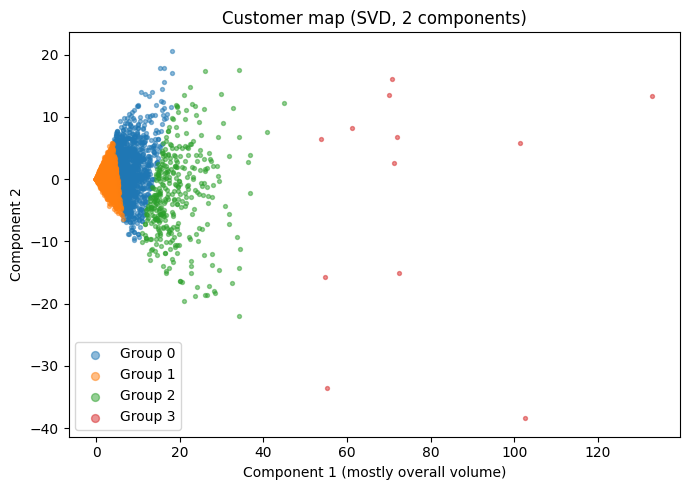

In [26]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

X = Z_svd[:, :2]                       # customer positions on SVD components 1 and 2

# 1. How many groups? Silhouette is a hint, not a verdict: also check the sizes.
sils = {}
for kk in range(3, 7):
    lab = KMeans(n_clusters=kk, n_init=10, random_state=SEED).fit_predict(X)
    sil = silhouette_score(X, lab, sample_size=3000, random_state=SEED)
    sils[kk] = (sil, np.bincount(lab).tolist())
    print(f"{kk} groups: silhouette {sil:.3f}, sizes {np.bincount(lab)}")

K_SEG = 4                              # <- change after reading the line above
seg = KMeans(n_clusters=K_SEG, n_init=10, random_state=SEED).fit_predict(X)

# 2. Country per customer (most common in training data), aligned to matrix rows
train = pd.read_parquet(f"{BASE}/data/processed/train.parquet")
cust_country = train.groupby("Customer ID")["Country"].agg(lambda s: s.mode().iloc[0])
cust = pd.read_csv(f"{BASE}/data/processed/customer_index.csv")
country = pd.Series(cust["customer_id"].map(cust_country).astype(str).to_numpy())

# 3. Profile each group
A_bin = (A > 0).tocsr()
overall = np.asarray(A_bin.mean(axis=0)).ravel()
n_products = np.asarray(A_bin.sum(axis=1)).ravel()
print("\nOverall: UK share =", f"{(country == 'United Kingdom').mean():.0%}",
      "| median distinct products per customer =", int(np.median(n_products)))

for s in range(K_SEG):
    idx = np.where(seg == s)[0]
    share = np.asarray(A_bin[idx].mean(axis=0)).ravel()      # share of group buying each product
    lift = share / overall                                    # >1 means over-represented
    ok = share >= 0.10                                        # ignore products few in the group buy
    by_lift = [j for j in np.argsort(-(lift * ok)) if ok[j]][:8]
    by_share = np.argsort(-share)[:5]
    print(f"\n=== Group {s}: {len(idx)} customers ({len(idx)/len(seg):.0%}) ===")
    print(f"distinct products bought: median {int(np.median(n_products[idx]))}")
    print("countries:", country.iloc[idx].value_counts(normalize=True).head(3).round(2).to_dict())
    print("most distinctive products (lift):")
    for j in by_lift: print(f"   {names[j]}  (lift {lift[j]:.1f}, {share[j]:.0%} of group)")
    print("most commonly bought:", [names[j] for j in by_share])

# 4. First-look map (no names yet, no IDs)
fig, ax = plt.subplots(figsize=(7, 5))
for s in range(K_SEG):
    m = seg == s
    ax.scatter(X[m, 0], X[m, 1], s=8, alpha=0.5, label=f"Group {s}")
ax.set_xlabel("Component 1 (mostly overall volume)")
ax.set_ylabel("Component 2")
ax.set_title("Customer map (SVD, 2 components)")
ax.legend(markerscale=2)
plt.tight_layout()
plt.savefig(f"{BASE}/outputs/customer_map_draft.png", dpi=150)
plt.show()

                                    Segment  Customers  % of customers  % of revenue  Median products bought  UK share %
                    Occasional small buyers       3994            73.0          23.0                      27          92
                    Home-décor & sign shops       1112            20.3          33.8                     122          92
Large children's & kitchen-ware wholesalers        353             6.5          30.6                     268          84
                               Key accounts         12             0.2          12.6                     839          67


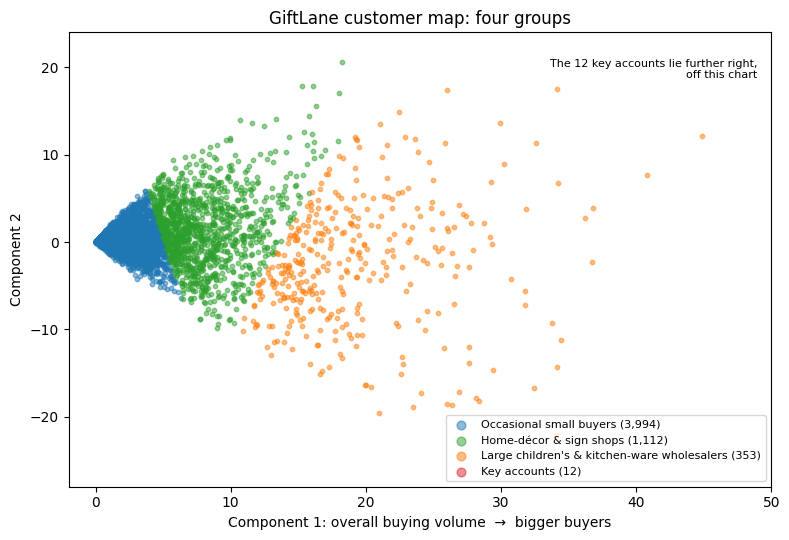

                                    Segment  Customers  % of customers  % of revenue  Median products bought  UK share %
                    Occasional small buyers       3994            73.0          23.0                      27          92
                    Home-décor & sign shops       1112            20.3          33.8                     122          92
Large children's & kitchen-ware wholesalers        353             6.5          30.6                     268          84
                               Key accounts         12             0.2          12.6                     839          67


In [27]:
import matplotlib.pyplot as plt

# Name groups by median products bought (robust to cluster label order)
med = {s: np.median(n_products[seg == s]) for s in range(K_SEG)}
order = sorted(med, key=med.get)
labels = ["Occasional small buyers", "Home-décor & sign shops",
          "Large children's & kitchen-ware wholesalers", "Key accounts"]
seg_name = {s: labels[i] for i, s in enumerate(order)}

# Revenue per customer in the training period (aggregated only: R4)
rev = (train["Quantity"] * train["Price"]).groupby(train["Customer ID"]).sum()
cust_rev = cust["customer_id"].map(rev).fillna(0).to_numpy()

rows = []
for s in order:
    m = seg == s
    rows.append({"Segment": seg_name[s], "Customers": int(m.sum()),
                 "% of customers": round(m.mean() * 100, 1),
                 "% of revenue": round(cust_rev[m].sum() / cust_rev.sum() * 100, 1),
                 "Median products bought": int(np.median(n_products[m])),
                 "UK share %": round((country[m] == "United Kingdom").mean() * 100)})
seg_table = pd.DataFrame(rows)
print(seg_table.to_string(index=False))
seg_table.to_csv(f"{BASE}/outputs/segments.csv", index=False)

# Final figure: zoomed on the main cloud, key accounts noted (no IDs anywhere)
colors = dict(zip(order, ["#1f77b4", "#2ca02c", "#ff7f0e", "#d62728"]))
fig, ax = plt.subplots(figsize=(8, 5.5))
for s in order:
    m = seg == s
    ax.scatter(X[m, 0], X[m, 1], s=10, alpha=0.5, color=colors[s],
               label=f"{seg_name[s]} ({m.sum():,})")
ax.set_xlim(-2, 50); ax.set_ylim(-28, 24)
ax.set_xlabel("Component 1: overall buying volume  \u2192  bigger buyers")
ax.set_ylabel("Component 2")
ax.set_title("GiftLane customer map: four groups")
ax.text(49, 21, "The 12 key accounts lie further right,\noff this chart", ha="right", va="top", fontsize=8)
ax.legend(fontsize=8, loc="lower right", markerscale=2)
plt.tight_layout()
plt.savefig(f"{BASE}/outputs/customer_map.png", dpi=200)
plt.show()

sil_txt = "; ".join(f"{k} groups {v[0]:.3f} (sizes {sorted(v[1], reverse=True)})" for k, v in sils.items())
seg_lines = "\n".join(
    f"- {r['Segment']}: {r['% of customers']}% of customers, {r['% of revenue']}% of revenue, "
    f"median {r['Median products bought']} products, UK share {r['UK share %']}%."
    for _, r in seg_table.iterrows())
with open(f"{BASE}/decision_log.md", "a") as f:
    f.write(f"""
## ML6 Customer map
- KMeans on the first 2 SVD components of the customer factors. Silhouette by number of groups: {sil_txt}.
- Every solution from 3 to 6 groups contains a tiny group of about 12 customers (the key accounts). We chose {K_SEG} groups because it also separates two mid-size groups that marketing can name (home-decor and sign shops; children's and kitchen-ware wholesalers).
- Groups mostly separate by SIZE (component 1 is overall volume); the taste signal in component 2 is weaker. The small-buyer group has no product with lift above 1 among products at least 10% of it buys, so it is defined by buying little, not by a taste.
- Key accounts (12 customers): lift values are noise at that size, so they are described by volume only.
- Lift is bounded by 1/group share, so lifts are not comparable across groups.
- Only aggregates and anonymised group labels are shown (R4).

## ML6 final segments (training-period revenue, before returns)
{seg_lines}
- Figure: outputs/customer_map.png, zoomed on the main cloud, key accounts noted off-chart, no customer IDs (R4).
""")
print(seg_table.to_string(index=False))

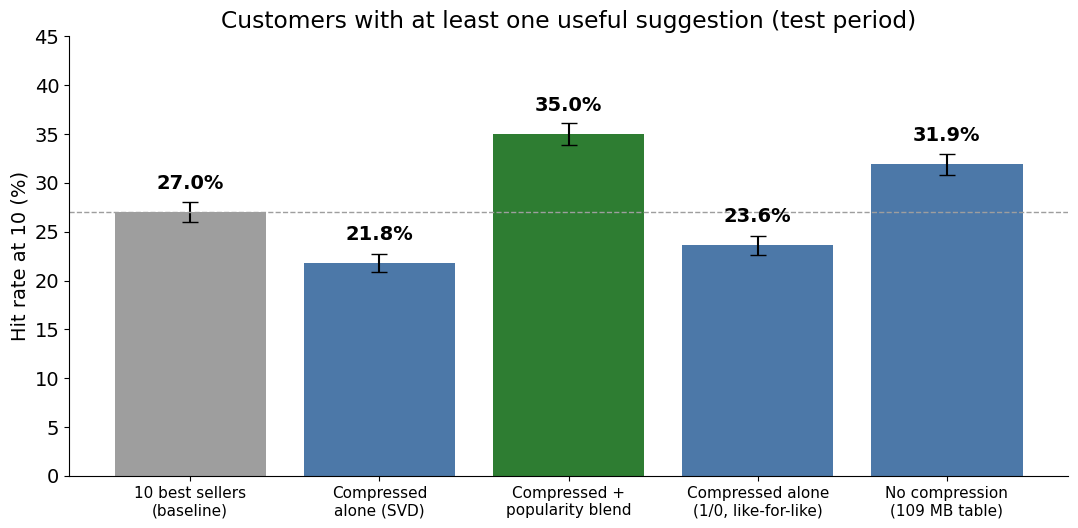

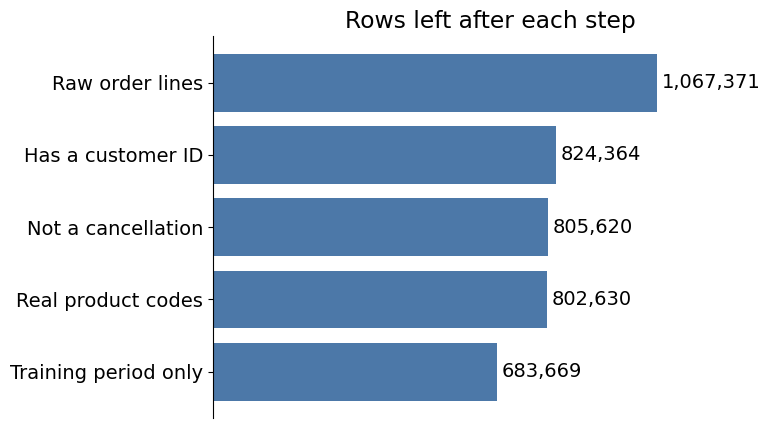

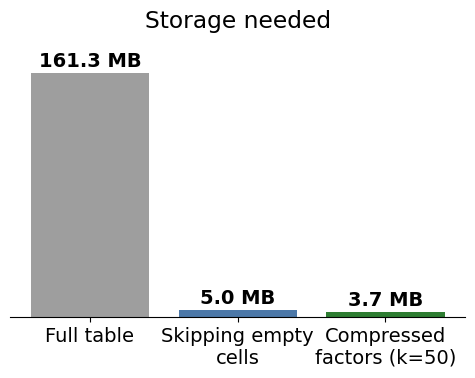

                                                    method  hit_rate  se
                                10 best sellers (baseline)      27.0 1.0
                      SVD k=50, log-quantity matrix, alone      21.8 0.9
SVD k=50 + popularity blend (w=2)  <- chosen on validation      35.0 1.1
                    SVD k=50 on 1/0 matrix (like-for-like)      23.6 1.0
            No compression: item-item cosine on 1/0 matrix      31.9 1.1
['Raw order lines', 'Has a customer ID', 'Not a cancellation', 'Real product codes', 'Training period only'] [1067371, 824364, 805620, 802630, 683669]
[np.float64(161.3), np.float64(5.0), np.float64(3.7)]


In [28]:
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt

OUT = f"{BASE}/outputs/slides"
os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({"font.size": 14, "axes.spines.top": False, "axes.spines.right": False})

# Every number below is read from files the pipeline saved: nothing is typed in.
dg = pd.read_csv(f"{BASE}/outputs/diagnostics_hit_rate.csv")
clog = pd.read_csv(f"{BASE}/outputs/cleaning_log.csv")
mrep = pd.read_csv(f"{BASE}/outputs/matrix_report.csv", index_col=0).iloc[:, 0]
srep = pd.read_csv(f"{BASE}/outputs/split_report.csv", index_col=0)
fit_rows = int(float(srep.loc["fit_rows", "test (final)"]))
assert len(dg) == 5, "diagnostics table should have 5 rows (baseline, SVD, blend, SVD 1/0, no compression)"

# ---- Chart 1: hit rate ----
n_prod = int(mrep["products (columns)"])
labels = ["10 best sellers\n(baseline)", "Compressed\nalone (SVD)", "Compressed +\npopularity blend",
          "Compressed alone\n(1/0, like-for-like)", f"No compression\n({n_prod**2 * 8 / 1e6:.0f} MB table)"]
rates, errs = dg["hit_rate"].tolist(), dg["se"].tolist()
colors = ["#9e9e9e", "#4c78a8", "#2e7d32", "#4c78a8", "#4c78a8"]
fig, ax = plt.subplots(figsize=(11, 5.5))
bars = ax.bar(labels, rates, yerr=errs, capsize=6, color=colors)
for b, r in zip(bars, rates):
    ax.text(b.get_x() + b.get_width() / 2, r + 2.4, f"{r}%", ha="center", fontweight="bold")
ax.axhline(rates[0], ls="--", color="#9e9e9e", lw=1)
ax.tick_params(axis="x", labelsize=11)
ax.set_ylabel("Hit rate at 10 (%)")
ax.set_ylim(0, max(rates) + 10)
ax.set_title("Customers with at least one useful suggestion (test period)")
plt.tight_layout(); plt.savefig(f"{OUT}/hit_rate_chart.png", dpi=200); plt.show()

# ---- Chart 2: cleaning funnel (steps that remove at least 1,000 rows) ----
friendly = {1: "Has a customer ID", 2: "Not a cancellation", 3: "Quantity above zero",
            4: "Price above zero", 5: "Real product codes", 6: "Not a reversed order"}
clog["n"] = clog["rule"].str.extract(r"^(\d+)\.")[0].astype(int)
steps, counts = ["Raw order lines"], [int(clog["rows_before"].iloc[0])]
for _, r in clog.iterrows():
    if r["rows_removed"] >= 1000:
        steps.append(friendly[int(r["n"])]); counts.append(int(r["rows_after"]))
counts[-1] = int(clog["rows_after"].iloc[-1])   # include the 2-row step hidden above
steps.append("Training period only"); counts.append(fit_rows)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(steps, counts, color="#4c78a8")
ax.invert_yaxis()
for i, c in enumerate(counts):
    ax.text(c + max(counts) * 0.01, i, f"{c:,}", va="center")
ax.set_xlim(0, max(counts) * 1.25)
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.set_title("Rows left after each step")
plt.tight_layout(); plt.savefig(f"{OUT}/cleaning_funnel.png", dpi=200); plt.show()

# ---- Chart 3: size ----
mb = [mrep["dense memory (MB)"], mrep["sparse CSR memory (MB)"], mrep["factors at k=50 (MB)"]]
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(["Full table", "Skipping empty\ncells", "Compressed\nfactors (k=50)"], mb,
              color=["#9e9e9e", "#4c78a8", "#2e7d32"])
for b, v in zip(bars, mb):
    ax.text(b.get_x() + b.get_width() / 2, v + max(mb) * 0.025, f"{v:.1f} MB", ha="center", fontweight="bold")
ax.set_ylim(0, max(mb) * 1.15)
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.set_title("Storage needed")
plt.tight_layout(); plt.savefig(f"{OUT}/size_chart.png", dpi=200); plt.show()

print(dg.to_string(index=False)); print(steps, counts); print(mb)

In [29]:
import importlib.metadata as md, sys
pkgs = ["pandas", "numpy", "scipy", "scikit-learn", "matplotlib", "pyarrow", "openpyxl"]
lines = [f"{p}=={md.version(p)}" for p in pkgs]
with open(f"{BASE}/requirements.txt", "w") as f:
    f.write("\n".join(lines) + "\n")
print("\n".join(lines))
print("Python", sys.version.split()[0])

pandas==2.2.3
numpy==2.1.3
scipy==1.16.3
scikit-learn==1.6.1
matplotlib==3.10.0
pyarrow==23.0.1
openpyxl==3.1.5
Python 3.13.16


In [30]:
import glob, re
ids = set(map(str, pd.read_csv(f"{BASE}/data/processed/customer_index.csv")["customer_id"]))
files = (glob.glob(f"{BASE}/outputs/**/*.csv", recursive=True)
         + glob.glob(f"{BASE}/outputs/**/*.md", recursive=True)
         + [f"{BASE}/decision_log.md"])
for f in files:
    hits = ids & set(re.findall(r"\b\d{5}\b", open(f, errors="ignore").read()))
    print(os.path.basename(f), "->", sorted(hits)[:5] if hits else "clean")

data_profile.csv -> clean
cleaning_log.csv -> clean
split_report.csv -> clean
matrix_report.csv -> clean
svd_k_curve.csv -> clean
svd_hit_rate_by_k.csv -> clean
pca_vs_svd_table.csv -> clean
segments.csv -> clean
diagnostics_hit_rate.csv -> clean
tuning_grid_validation.csv -> clean
nightly_timing.csv -> clean
ml1_decision_note.md -> clean
decision_log.md -> clean
